# Image Alignment 
also reffered as image registration


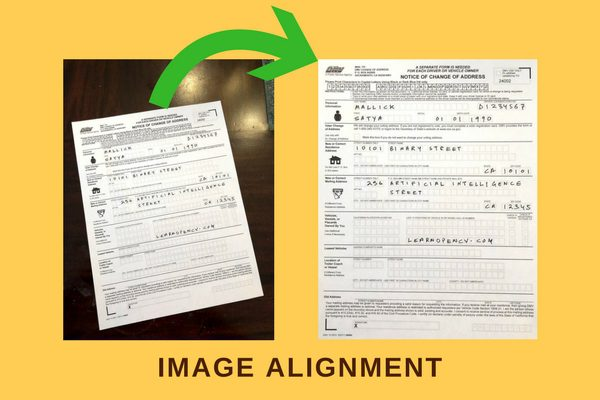


# Theory
A Homography transforms a square to arbitrary quad.


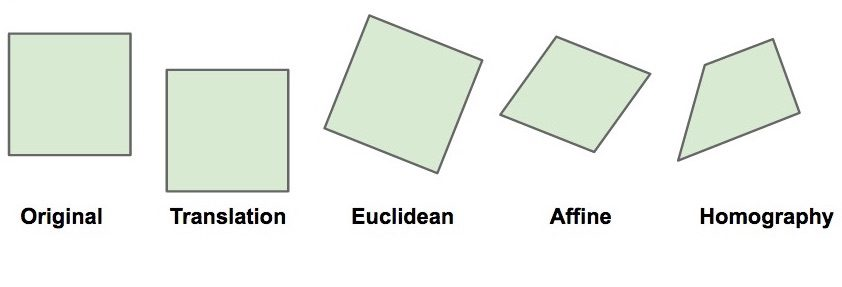


# Theory
1. Images of two planes are related by a Homography
2. We need __4 corresponding points__ to estimate Homography


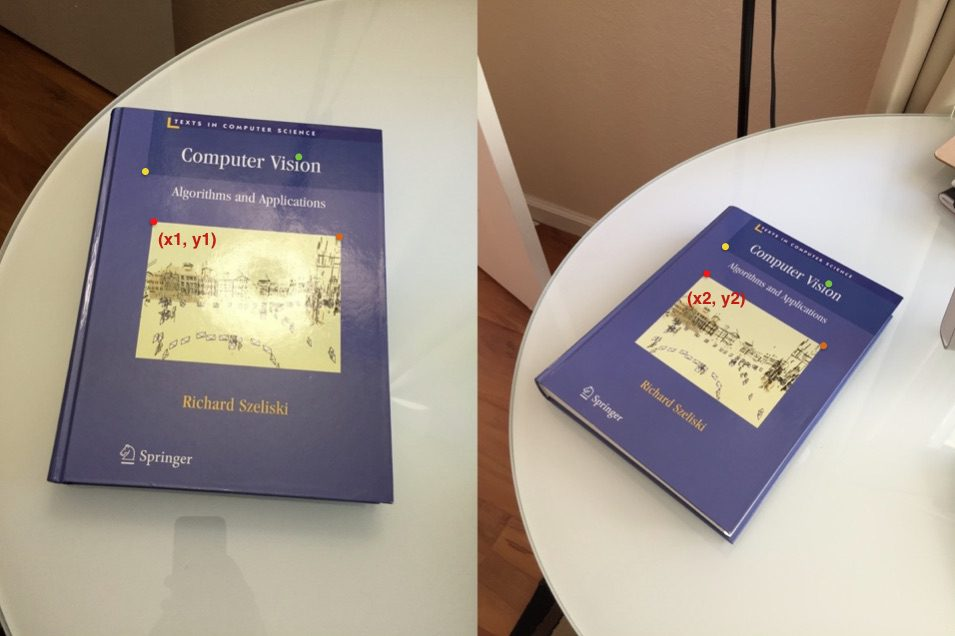

In [1]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

from zipfile import ZipFile
from urllib.request import urlretrieve

%matplotlib inline

In [2]:
def download_and_unzip(url, save_path):
    print(f"Downloading and extracting assests...", end="")

    urlretrieve(url, save_path)

    try:
        with ZipFile(save_path) as z:
            z.extractall(os.path.split(save_path)[0])
        print("Done")
    except Exception as e:
        print("\nInvalid file.", e)

        

In [3]:
URL = r"https://www.dropbox.com/s/zuwnn6rqe0f4zgh/opencv_bootcamp_assets_NB8.zip?dl=1"

asset_zip_path = os.path.join(os.getcwd(), f"opencv_bootcamp_assets_NB8.zip")

if not os.path.exists(asset_zip_path):
    download_and_unzip(URL, asset_zip_path)



# Step 1: Read Template and Scanned Image


In [4]:
# Read reference image
refFilename = "form.jpg"
print("Reading reference image : ", refFilename)
im1 = cv2.imread(refFilename, cv2.IMREAD_COLOR)
im1 = cv2.cvtColor(im1, cv2.COLOR_BGR2RGB)


# Read image to be aligned
imFilename = "scanned-form.jpg"
print("Reading image to align:", imFilename)
im2 = cv2.imread(imFilename, cv2.IMREAD_COLOR)
im2 = cv2.cvtColor(im2, cv2.COLOR_BGR2RGB)

Reading reference image :  form.jpg
Reading image to align: scanned-form.jpg


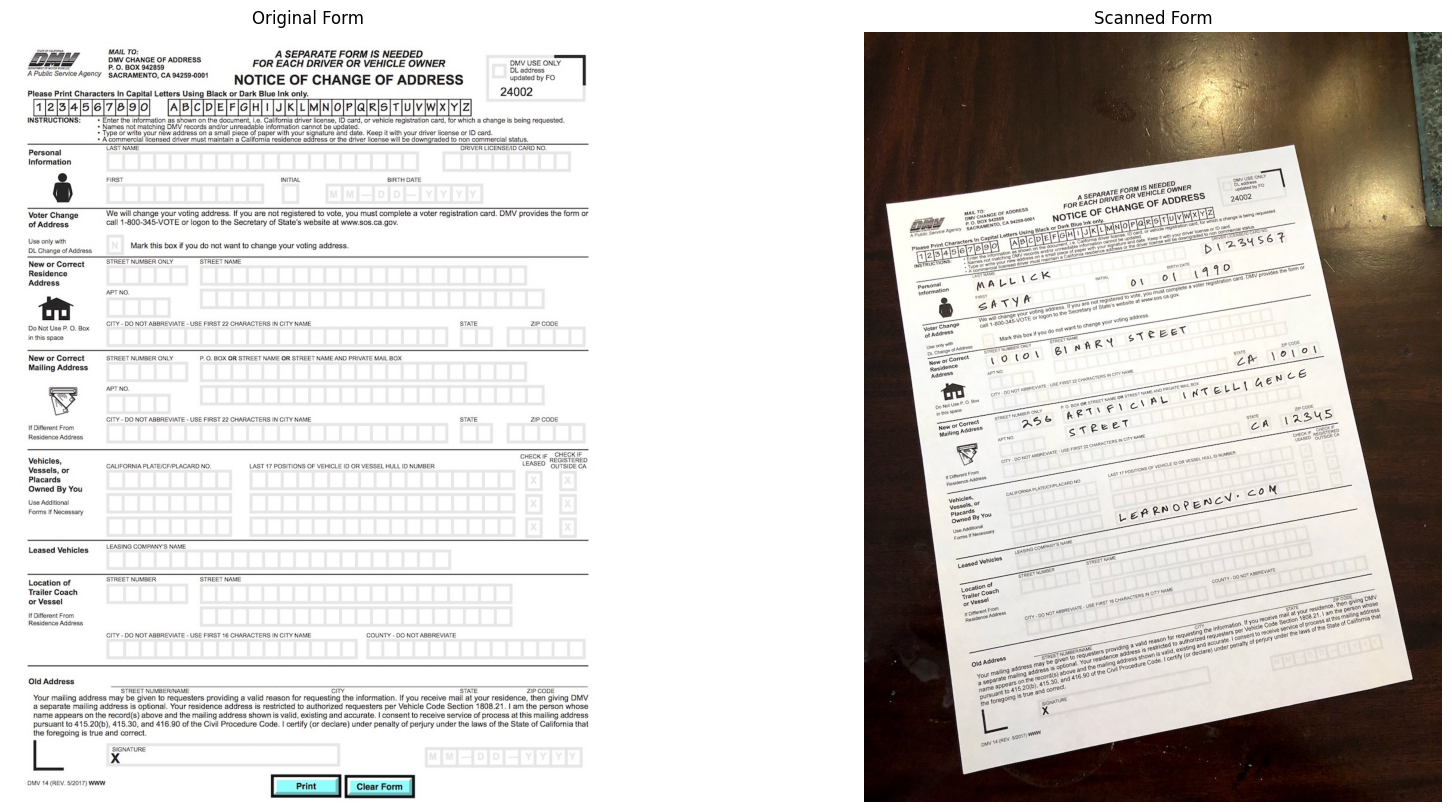

In [5]:
# Display Images

plt.figure(figsize=[20,10])
plt.subplot(121); plt.axis('off'); plt.imshow(im1); plt.title("Original Form")
plt.subplot(122); plt.axis('off'); plt.imshow(im2); plt.title("Scanned Form")

plt.show()

# Step 2: Find keypoints in both images
Think of keypoints as corner points that are stable under image transformations

In [12]:
# Convert images to grayscale
im1_gray = cv2.cvtColor(im1, cv2.COLOR_BGR2GRAY)
im2_gray = cv2.cvtColor(im2, cv2.COLOR_BGR2GRAY)

# Detect ORB features and compute descriptors
MAX_NUM_FEATURES = 500
orb = cv2.ORB_create(MAX_NUM_FEATURES)
keypoints1, descriptors1 = orb.detectAndCompute(im1_gray, None)
keypoints2, descriptors2 = orb.detectAndCompute(im2_gray, None)

# Display
im1_display = cv2.drawKeypoints(im1, keypoints1, outImage=np.array([]), color = (255, 0, 0), flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
im2_display = cv2.drawKeypoints(im2, keypoints2, outImage=np.array([]), color = (255, 0, 0), flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS )

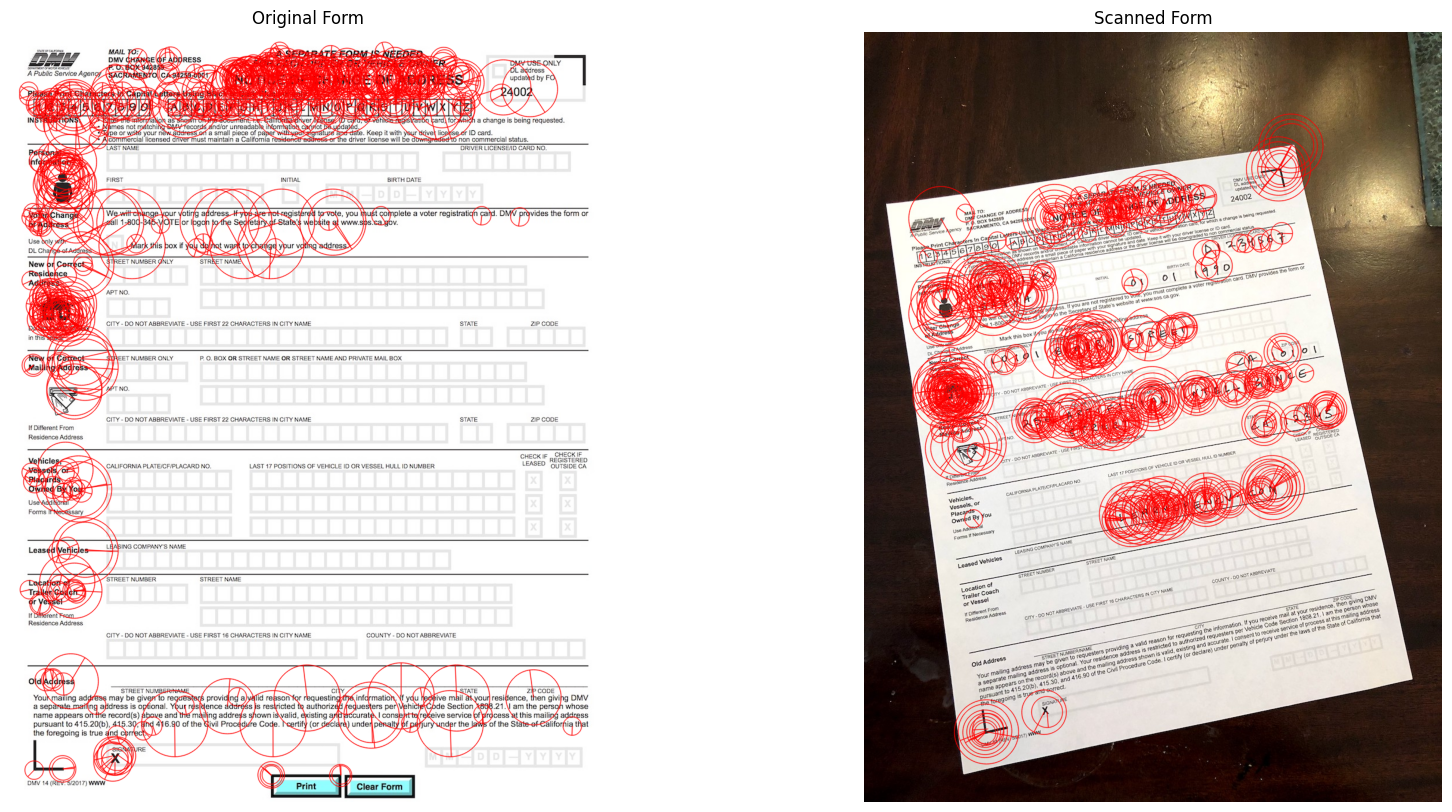

In [13]:
plt.figure(figsize=[20,10])
plt.subplot(121); plt.axis('off'); plt.imshow(im1_display); plt.title("Original Form");
plt.subplot(122); plt.axis('off'); plt.imshow(im2_display); plt.title("Scanned Form");

plt.show()

# Step 3: Match keypoints in the two image

In [19]:
# Match features.
matcher = cv2.DescriptorMatcher_create(cv2.DESCRIPTOR_MATCHER_BRUTEFORCE_HAMMING)
matches = matcher.match(descriptors1, descriptors2, None)

# Sort matches by scores
# matches.sort(key=lambda x: x.distance, reverse=False)

# Sort matches by scores (using sorted() instead of .sort())
matches = sorted(matches, key=lambda x: x.distance, reverse=False)

# Remove not so good matches
numGoodMatches = int(len(matches) * 0.1) # limiting top 10%
matches = matches[:numGoodMatches]



__cv2.DescriptorMatcher_create(2)__


| Integer Value | OpenCV Constant | Matching Method & Distance Metric |
| :--- | :--- | :--- |
| **1** | `cv2.DESCRIPTOR_MATCHER_FLANNBASED` | FLANN-based matcher (fast approximate nearest neighbor). |
| **2** | `cv2.DESCRIPTOR_MATCHER_BRUTEFORCE` | Brute-Force matcher using L2 (Euclidean) distance. |
| **3** | `cv2.DESCRIPTOR_MATCHER_BRUTEFORCE_L1` | Brute-Force matcher using L1 (Manhattan) distance. |
| **4** | `cv2.DESCRIPTOR_MATCHER_BRUTEFORCE_HAMMING` | Brute-Force matcher using Hamming distance. |
| **5** | `cv2.DESCRIPTOR_MATCHER_BRUTEFORCE_HAMMINGLUT` | Brute-Force matcher using Hamming distance with lookup tables. |
| **6** | `cv2.DESCRIPTOR_MATCHER_BRUTEFORCE_SL2` | Brute-Force matcher using squared L2 distance. |


__Newer versions of OpenCV return matches as an immutable tuple instead of a mutable list, and tuples do not have a built-in .sort() method.__

In [18]:
type(matches)

list

In [25]:
matches

[< cv2.DMatch 00000279B4E06270>,
 < cv2.DMatch 00000279B4E062D0>,
 < cv2.DMatch 00000279B4E069F0>,
 < cv2.DMatch 00000279B4E040B0>,
 < cv2.DMatch 00000279B4E040D0>,
 < cv2.DMatch 00000279B4E05950>,
 < cv2.DMatch 00000279B4E06090>,
 < cv2.DMatch 00000279B4E04DD0>,
 < cv2.DMatch 00000279B4E04E70>,
 < cv2.DMatch 00000279B4E06B90>,
 < cv2.DMatch 00000279B4E04B50>,
 < cv2.DMatch 00000279B4E060B0>,
 < cv2.DMatch 00000279B4E04A30>,
 < cv2.DMatch 00000279B4E057D0>,
 < cv2.DMatch 00000279B4E06D90>,
 < cv2.DMatch 00000279B4E06CB0>,
 < cv2.DMatch 00000279B4E06830>,
 < cv2.DMatch 00000279B4E06670>,
 < cv2.DMatch 00000279B4E04730>,
 < cv2.DMatch 00000279B4E06390>,
 < cv2.DMatch 00000279B4E06D10>,
 < cv2.DMatch 00000279B4E07430>,
 < cv2.DMatch 00000279B4E05F10>,
 < cv2.DMatch 00000279B4E06690>,
 < cv2.DMatch 00000279B4E04630>,
 < cv2.DMatch 00000279B4E04770>,
 < cv2.DMatch 00000279B4E05C50>,
 < cv2.DMatch 00000279B4E045D0>,
 < cv2.DMatch 00000279B4E05CF0>,
 < cv2.DMatch 00000279B4E06B30>,
 < cv2.DMa

In [34]:
len(matches)

50

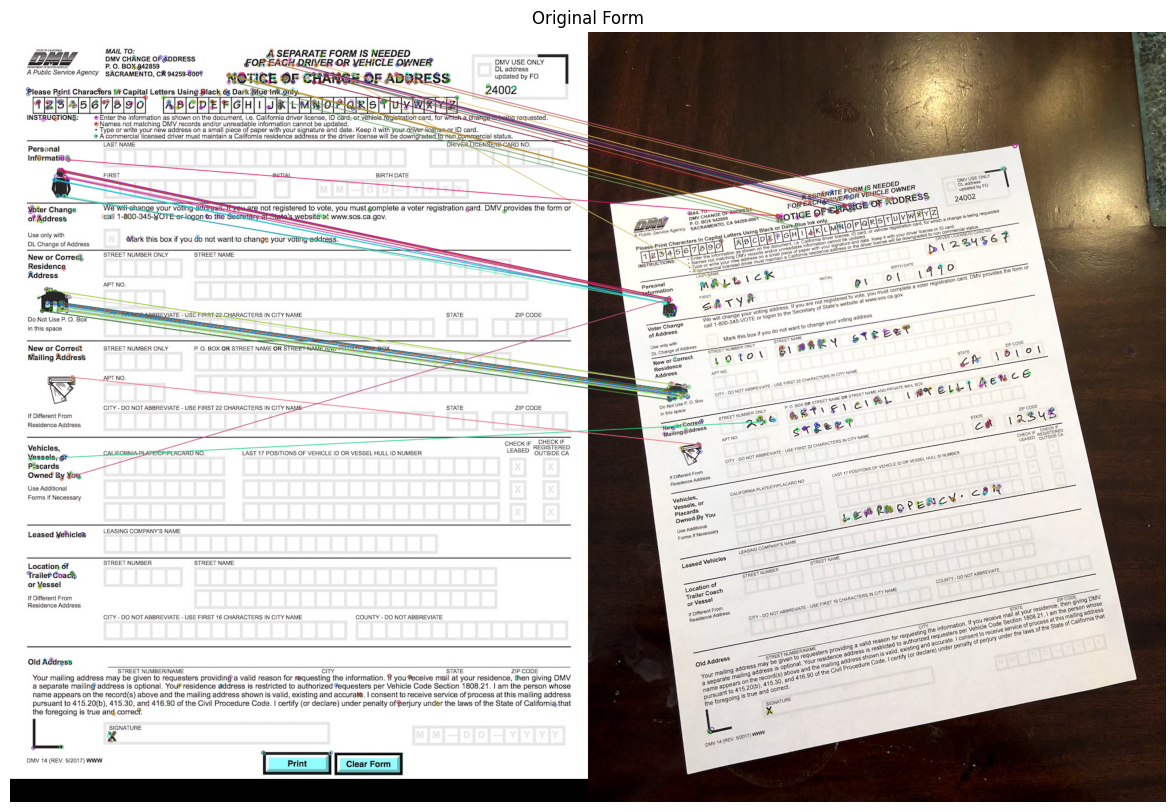

In [22]:
# Draw top matches

im_matches = cv2.drawMatches(im1, keypoints1, im2, keypoints2, matches, None)

plt.figure(figsize=[40, 10])
plt.imshow(im_matches); plt.axis('off'); plt.title("Original Form")

plt.show()

# Step 4: Find Homography

In [35]:
# Exact location of good matches

points1 = np.zeros((len(matches), 2), dtype= np.float32)
points2 = np.zeros((len(matches), 2), dtype= np.float32)

for i, match in enumerate(matches):
    points1[i, :] = keypoints1[match.queryIdx].pt
    points2[i, :] = keypoints2[match.trainIdx].pt

# Find homography
h, mask = cv2.findHomography(points2, points1, cv2.RANSAC)

• Step 1 — Calculate the Matrix (cv2.getPerspectiveTransform() or cv2.findHomography()): This function takes your matching (x, y) coordinates and computes the 3×3 transformation matrix (h). It does not touch or change any pixels in your image.

• Step 2 — Apply the Matrix (cv2.warpPerspective()): This function takes your actual image (im2) and that 3×3 matrix (h), and moves every pixel into its new position to produce the straightened image.


# Step 5: Wrap Image

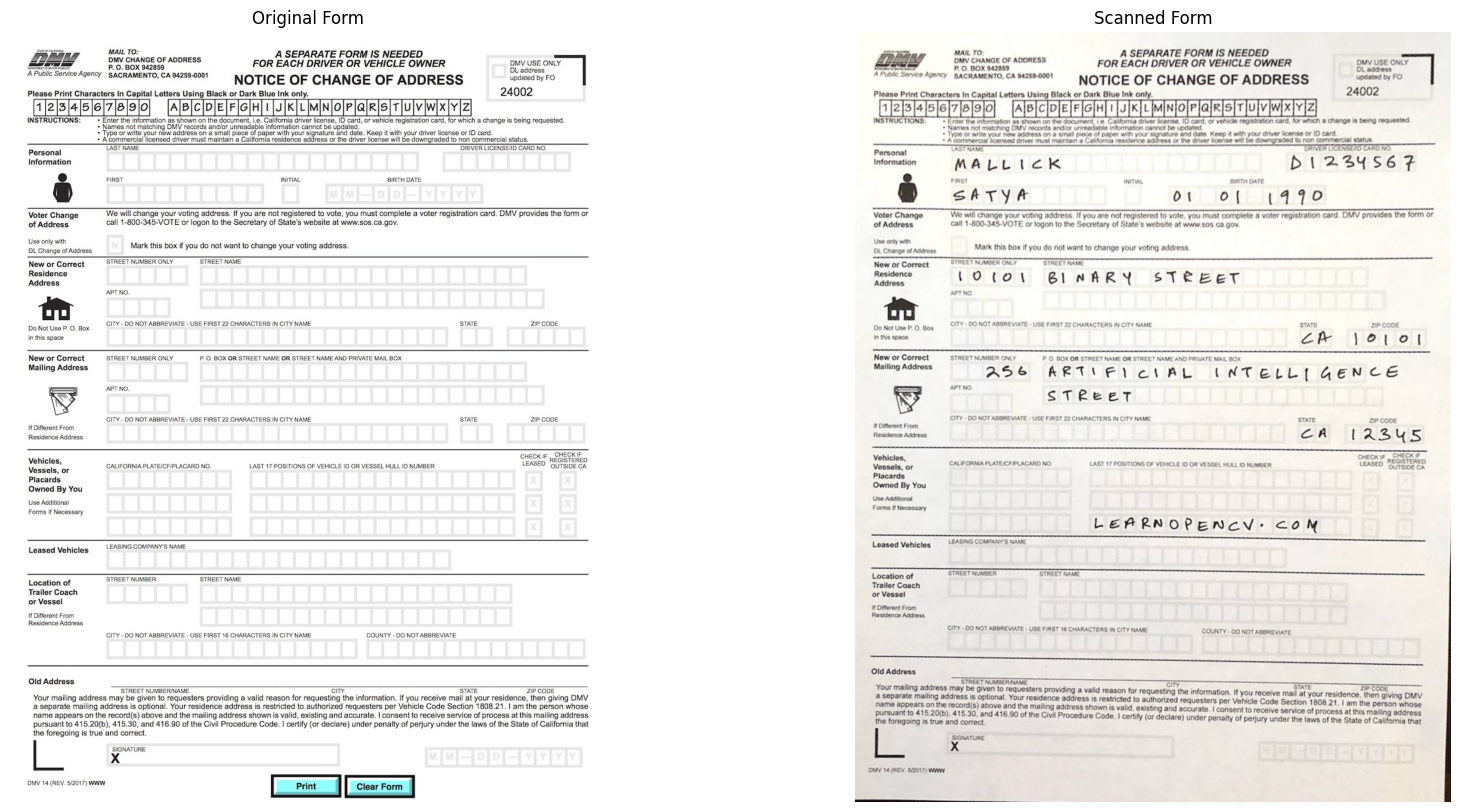

In [38]:
# Use homography to warp image
height, width, channels = im1.shape
im2_reg = cv2.warpPerspective(im2, h, (width, height))

# Display results
plt.figure(figsize=[20,10])
plt.subplot(121); plt.imshow(im1); plt.axis('off'); plt.title("Original Form");
plt.subplot(122); plt.imshow(im2_reg); plt.axis('off'); plt.title("Scanned Form");

plt.show()

• 1. Finding the Location (Keypoint): When ORB scans your form, it spots a sharp corner on a checkbox at pixel (x=120, y=340) tilted at 15°. That location data is saved as a Keypoint.

• 2. Describing the Appearance (Descriptor): ORB then zooms into the tiny patch of pixels around (120, 340) and generates a 256-bit binary code summarizing its light-and-dark pattern. That code is the Descriptor (the ORB vector).

• 3. Matching and Aligning: The matcher compares descriptors between the Original Form and Scanned Form to find pairs with matching fingerprints. Once a match is confirmed, your code grabs the (x, y) coordinates from their keypoints to warp and straighten the page.
